## Water Levels at Banagher Bridge, River Shannon

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb
from datetime import datetime
from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score
from sklearn.model_selection import RandomizedSearchCV,GridSearchCV

colour_pal = sns.color_palette()
#plt.style.use('fivethirtyeight') # - I am not sure I like this

# https://www.youtube.com/watch?v=vV12dGe_Fho&t=132s
# https://waterlevel.ie/hydro-data/#/overview/Waterlevel/station/11617/Banagher/Qdownload
## correct for height above malin head
height = 30.330 # this is height of sensor 25017 above Malin Head
#df['DayMin'] = df['DayMin'] - height
'''
I want to calculate the floodline here, 
## Suggest last thursday is 3 feet above flood. - Dec 2023, check data for exact date!
Find scalar for flood level in M. 
also import mean and percentile values from the waterlevels website, and compare them.
'''

#importing the datasets
# this dataset has the hourly readouts.
df = pd.read_csv('tsvalues.csv', sep=';', skiprows=10).iloc[:, :-1] # drop the water quality for now
df['Timestamp'] = df['#Timestamp']

df = df.set_index('Timestamp') # set the index

#issue is data is set = "%d/%m/%Y" - this should make this ok.
df.index = pd.to_datetime(df.index, format='mixed', dayfirst=True)
df['Value'] = df['Value'] - height # to recalibrate water level, keep colname value for now.

# this dataset has one datapoint for each day. # dataset 2
df2 = pd.read_csv('25017_banagher_s_complete.csv', skiprows=12).iloc[:, :-1] # for now exclude the quality column

df2 = df2.set_index('Day') # set the index

#issue is data is set = "%d/%m/%Y" - this should make this ok.
df2.index = pd.to_datetime(df2.index, format='mixed', dayfirst=True)

# to recalibrate water levels
df2['Day Min'] = df2['Day Min'] - height 
df2['Day Mean'] = df2['Day Mean'] - height 
df2['Day Max'] = df2['Day Max'] - height 

# some more work may be needed here

In [2]:
df2.head()
#df.tail()
#df.index

,Day Min,Day Mean,Day Max
Day,,,
1989-01-02,2.905,2.95,2.982
1989-01-03,2.774,2.84,2.905
1989-01-04,2.757,2.76,2.774
1989-01-05,2.764,2.81,2.874
1989-01-06,2.874,2.97,3.037


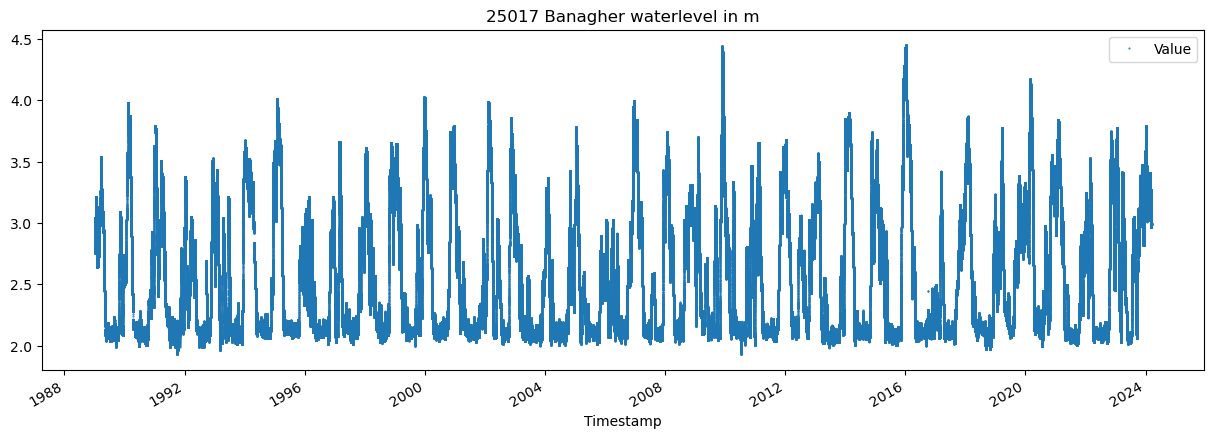

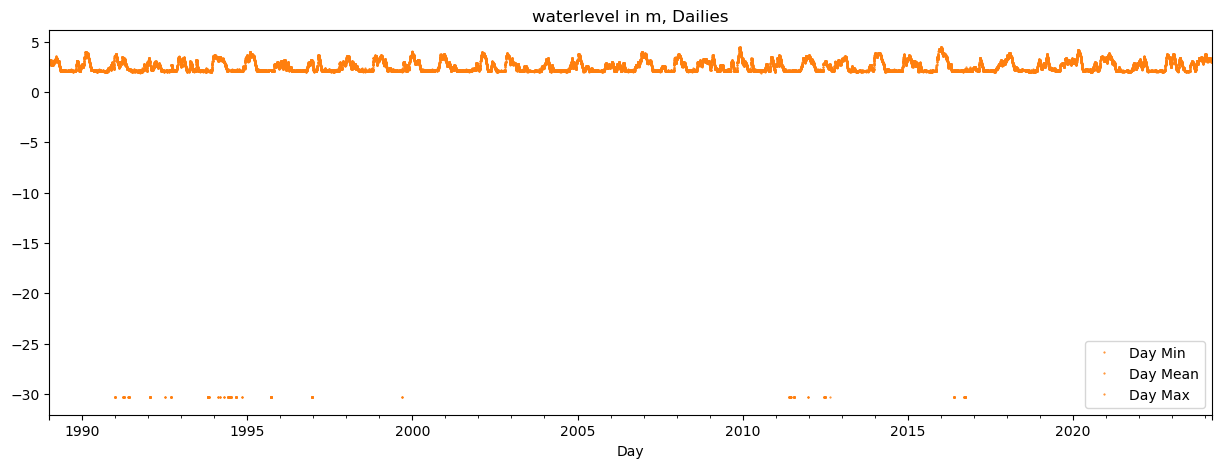

In [3]:
df.plot(style='.', 
        figsize=(15,5), 
        color=colour_pal[0], 
        title='25017 Banagher waterlevel in m',
        markersize=1)
plt.show()

df2.plot(style='.', 
        figsize=(15,5), 
        color=colour_pal[1], 
        title='waterlevel in m, Dailies',
        markersize=1)
plt.show()

# issues here with zeros on the second plot but I will come to fix this, by removing the outliers.


In [4]:
#df.index

## Train / Test Split

In [5]:
# later I will change this to full cross validation
#https://machinelearningmastery.com/xgboost-for-regression/
#I should be able to replace with this

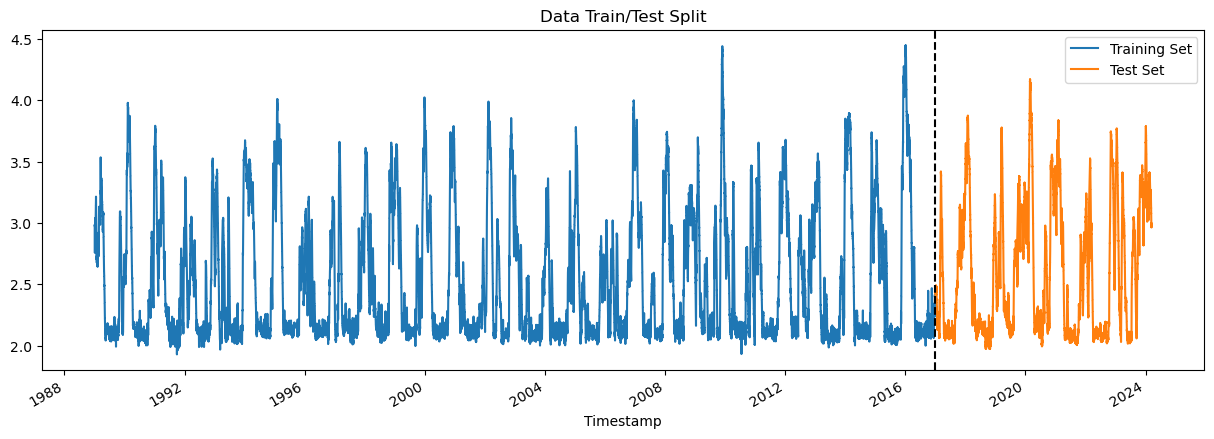

In [6]:
train = df.loc[df.index < '01-01-2017']
test = df.loc[df.index >= '01-01-2017']

fig, ax = plt.subplots(figsize=(15, 5))
train.plot(ax=ax, label='Training Set', title='Data Train/Test Split')
test.plot(ax=ax, label='Test Set')

ax.axvline('01-01-2017', color='black', ls='--')
ax.legend(['Training Set', 'Test Set'])
plt.show()


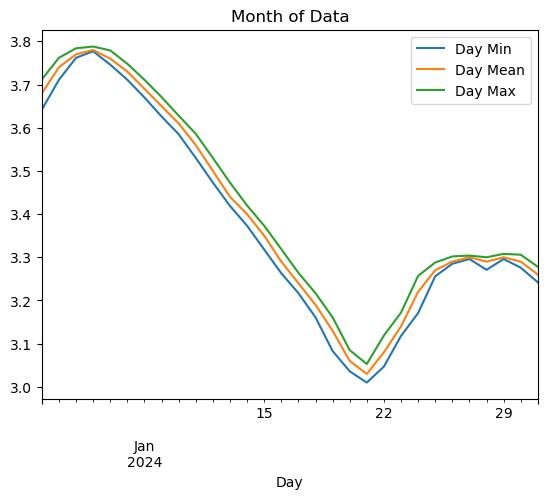

In [7]:
# weekly plot, or monthly
df2.loc[(df2.index > '01-01-2024') & (df2.index <= '31-01-2024')].plot(title='Month of Data') 
plt.show()

# the weekly seems trivial, but the monthly is relevant with the daily data.
# maybe I will revisit this and put in a number of months where we want some detail.
# quarterly here might actually be better, for the months where there is risk of flood water.

### Feature Creation

In [8]:
df.index

DatetimeIndex(['1989-01-02 09:00:00+00:00', '1989-01-02 09:15:00+00:00',
               '1989-01-02 09:30:00+00:00', '1989-01-02 09:45:00+00:00',
               '1989-01-02 10:00:00+00:00', '1989-01-02 10:15:00+00:00',
               '1989-01-02 10:30:00+00:00', '1989-01-02 10:45:00+00:00',
               '1989-01-02 11:00:00+00:00', '1989-01-02 11:15:00+00:00',
               ...
               '2024-03-13 22:15:00+00:00', '2024-03-13 22:30:00+00:00',
               '2024-03-13 22:45:00+00:00', '2024-03-13 23:00:00+00:00',
               '2024-03-13 23:15:00+00:00', '2024-03-13 23:30:00+00:00',
               '2024-03-13 23:45:00+00:00', '2024-03-14 00:00:00+00:00',
               '2024-03-14 00:15:00+00:00', '2024-03-14 00:30:00+00:00'],
              dtype='datetime64[ns, UTC]', name='Timestamp', length=1218710, freq=None)

In [9]:
df2.index

DatetimeIndex(['1989-01-02', '1989-01-03', '1989-01-04', '1989-01-05',
               '1989-01-06', '1989-01-07', '1989-01-08', '1989-01-09',
               '1989-01-10', '1989-01-11',
               ...
               '2024-03-04', '2024-03-05', '2024-03-06', '2024-03-07',
               '2024-03-08', '2024-03-09', '2024-03-10', '2024-03-11',
               '2024-03-12', '2024-03-13'],
              dtype='datetime64[ns]', name='Day', length=12855, freq=None)

In [10]:
def create_features(df):
    '''
    Create time series features based on time series index.
    '''
    df = df.copy()
    df['hour'] = df.index.hour # trivial for waterlevels
    df['dayofweek'] = df.index.day_of_week # trivial for waterlevels
    df['quarter'] = df.index.quarter # not interesting for waterlevels
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.day_of_year
    return df

df = create_features(df)

def create_features_simple(df):
    '''
    Create time series features based on time series index.
    The function that looks at the average daily values can be used for year on year comparison
    '''    
    df['dayofweek'] = df.index.day_of_week # trivial for waterlevels
    df['quarter'] = df.index.quarter # not interesting for waterlevels
    df['month'] = df.index.month
    df['year'] = df.index.year
    df['dayofyear'] = df.index.day_of_year
    return df

df2 = create_features_simple(df2)

In [39]:
df.tail(10)

,#Timestamp,Value,hour,dayofweek,quarter,month,year,dayofyear
Timestamp,,,,,,,,
2024-03-13 22:15:00+00:00,2024-03-13T22:15:00.000Z,2.990,22,2,1,3,2024,73
2024-03-13 22:30:00+00:00,2024-03-13T22:30:00.000Z,2.991,22,2,1,3,2024,73
2024-03-13 22:45:00+00:00,2024-03-13T22:45:00.000Z,2.991,22,2,1,3,2024,73
2024-03-13 23:00:00+00:00,2024-03-13T23:00:00.000Z,2.991,23,2,1,3,2024,73
2024-03-13 23:15:00+00:00,2024-03-13T23:15:00.000Z,2.993,23,2,1,3,2024,73
2024-03-13 23:30:00+00:00,2024-03-13T23:30:00.000Z,2.994,23,2,1,3,2024,73
2024-03-13 23:45:00+00:00,2024-03-13T23:45:00.000Z,2.994,23,2,1,3,2024,73
2024-03-14 00:00:00+00:00,2024-03-14T00:00:00.000Z,2.995,0,3,1,3,2024,74
2024-03-14 00:15:00+00:00,2024-03-14T00:15:00.000Z,2.996,0,3,1,3,2024,74


In [38]:
df2.tail(10)

,Day Min,Day Mean,Day Max,dayofweek,quarter,month,year,dayofyear
Day,,,,,,,,
2024-03-04,3.207,3.23,3.251,0,1,3,2024,64
2024-03-05,3.180,3.20,3.217,1,1,3,2024,65
2024-03-06,3.204,3.21,3.221,2,1,3,2024,66
2024-03-07,3.178,3.19,3.206,3,1,3,2024,67
2024-03-08,3.140,3.16,3.180,4,1,3,2024,68
2024-03-09,3.092,3.12,3.141,5,1,3,2024,69
2024-03-10,3.035,3.07,3.093,6,1,3,2024,70
2024-03-11,2.977,3.00,3.035,0,1,3,2024,71
2024-03-12,2.967,2.97,2.978,1,1,3,2024,72


### Visualise our feature / target relationship

Text(0.5, 1.0, 'Waterlevel in M')

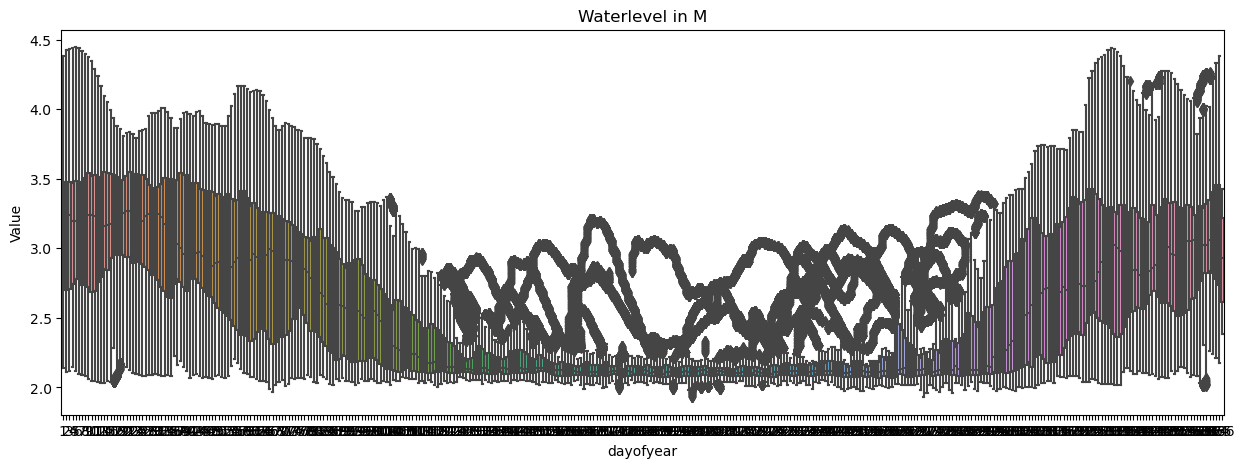

In [59]:
fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(data=df, x='dayofyear', y='Value') #whis=(1, 99)
ax.set_title('Waterlevel in M')
# this example here is too detailed, maybe I need to calculate a weekly average from the average of the daily averages.
# another trivial example here if I explore the other dataset.

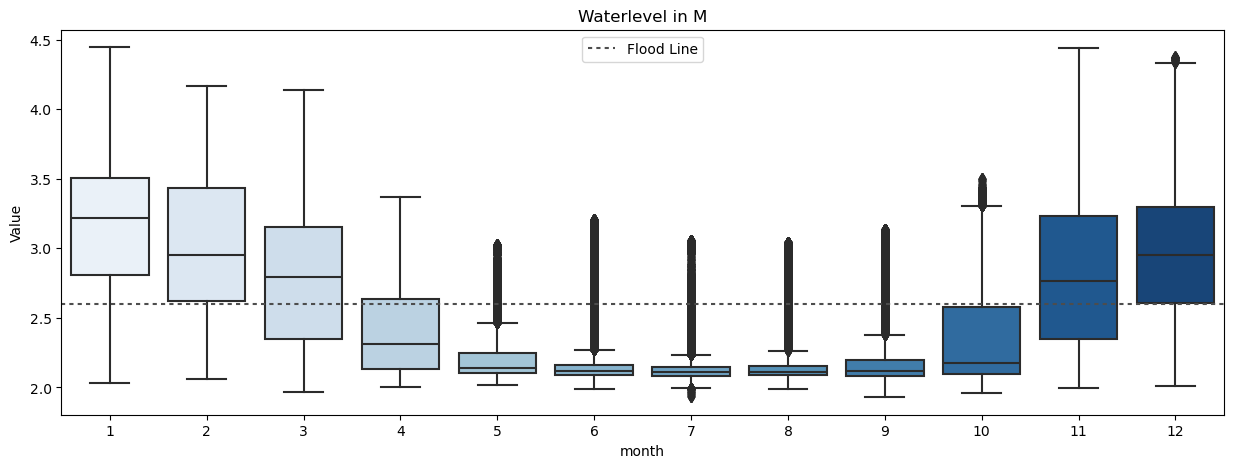

In [51]:
fig, ax = plt.subplots(figsize=(15,5))
sns.boxplot(data=df, x='month', y='Value', palette='Blues') # not sure if the whiskers and outliers ok. whis=(2, 98)
ax.set_title('Waterlevel in M')
# I should put in the floodline here, for average projection of flooding in the future
# this is an absolute guess for first order approximation.
ax.axhline(2.6, color=".3", dashes=(2, 2), label='Flood Line')
plt.legend()
plt.show()

There is more scope for plots here, insert lines for percentiles, day of the year trends, quarterly and monthly year on year comparison looking for waterlevels websites definition for what is in flood and our estimation for flood levels in the field.

I am starting with the 5 number summary, and I can add in those as lines in a second plot.

In [41]:
# should I count the numbers of outliers in the summer months? This box plot and the one above seem to show them, is that enough for me?

In [47]:
# calculate and print the 5 number summaries
'''
quartiles = np.percentile(df['Value'], [25, 50, 75])
data_min, data_max = df['Value'].min(), df['Value'].max()

# print 5-number summary
print('Min: %.3f' % data_min)
print('Q1: %.3f' % quartiles[0])
print('Median: %.3f' % quartiles[1])
print('Q3: %.3f' % quartiles[2])
print('Max: %.3f' % data_max)
'''

def summary(data): # more concise
    '''Seven-number summary, printing the results'''
    return np.percentile(data, [0, 10, 25, 50, 75, 90, 100], method="midpoint")

print([0, 10, 25, 50, 75, 90, 100])
print(summary(df['Value']))

[0, 10, 25, 50, 75, 90, 100]
[1.93  2.08  2.113 2.289 2.907 3.372 4.446]


In [44]:
# How do these compare to the ones on the Waterlevels website?

### My Chosen Model / Models
##### Regression model

In [16]:
train = create_features(train)
test = create_features(test)

FEATURES = ['hour', 'dayofweek', 'quarter', 'month', 'year', 'dayofyear']
TARGET = ['Value']

X_train = train[FEATURES]
y_train = train[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

# https://machinelearningmastery.com/tune-learning-rate-for-gradient-boosting-with-xgboost-in-python/
# I might edit this further, its KFOLD mixed in with SearchGrid, so I can check a number of hyperparameters.
# I am not sure how much time I should spend on the hyperparameters, I will plot some predicted points first and make the call.
# I can then exclude the test/train split, and the above notes on CV.


In [17]:
reg = xgb.XGBRegressor(n_estimators=1000, early_stopping_rounds=50) # is this accurate enough in this case?
reg.fit(X_train, y_train,
        eval_set=[(X_train, y_train), (X_test, y_test)],
        verbose=25)

[0]	validation_0-rmse:1.47761	validation_1-rmse:1.55768
[25]	validation_0-rmse:0.14186	validation_1-rmse:0.63322
[50]	validation_0-rmse:0.09427	validation_1-rmse:0.63714
[57]	validation_0-rmse:0.08549	validation_1-rmse:0.63803


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=50,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=1000, n_jobs=None, num_parallel_tree=None,
             predictor=None, random_state=None, ...)

I suspect there is overfitting here, so I will try again.

In [18]:
reg = xgb.XGBRegressor(n_estimators=3000, 
                       early_stopping_rounds=50,
                       learning_rate=0.005) # Regularization
reg.fit(X_train, y_train,
        eval_set=[(X_train, y_train), (X_test, y_test)],
        verbose=100)

[0]	validation_0-rmse:2.07732	validation_1-rmse:2.17135
[100]	validation_0-rmse:1.28012	validation_1-rmse:1.37040
[200]	validation_0-rmse:0.80498	validation_1-rmse:0.93854
[300]	validation_0-rmse:0.52674	validation_1-rmse:0.72806
[400]	validation_0-rmse:0.37168	validation_1-rmse:0.64330
[500]	validation_0-rmse:0.28924	validation_1-rmse:0.61498
[600]	validation_0-rmse:0.24587	validation_1-rmse:0.60951
[655]	validation_0-rmse:0.22973	validation_1-rmse:0.60947


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=50,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.005, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=3000, n_jobs=None, num_parallel_tree=None,
             predictor=None, random_state=None, ...)

In [19]:
# I'm going to try gridsearch to get the best hyperparameters.

In [ ]:
reg_cv = GridSearchCV(reg, {'max_depth': [3,4,6], 'n_estimators': [500,1000,2000,3000]}, verbose=100)

reg_cv.fit(X_train,y_train, eval_set=[(X_train, y_train), (X_test, y_test)]) # put the verbose here instead

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV 1/5; 1/12] START max_depth=3, n_estimators=500..............................
[0]	validation_0-rmse:2.07739	validation_1-rmse:2.17180
[1]	validation_0-rmse:2.06731	validation_1-rmse:2.16171
[2]	validation_0-rmse:2.05728	validation_1-rmse:2.15168
[3]	validation_0-rmse:2.04730	validation_1-rmse:2.14170
[4]	validation_0-rmse:2.03738	validation_1-rmse:2.13176
[5]	validation_0-rmse:2.02750	validation_1-rmse:2.12189
[6]	validation_0-rmse:2.01768	validation_1-rmse:2.11206
[7]	validation_0-rmse:2.00791	validation_1-rmse:2.10229
[8]	validation_0-rmse:1.99818	validation_1-rmse:2.09257
[9]	validation_0-rmse:1.98851	validation_1-rmse:2.08290
[10]	validation_0-rmse:1.97889	validation_1-rmse:2.07329
[11]	validation_0-rmse:1.96931	validation_1-rmse:2.06372
[12]	validation_0-rmse:1.95979	validation_1-rmse:2.05420
[13]	validation_0-rmse:1.95031	validation_1-rmse:2.04474
[14]	validation_0-rmse:1.94089	validation_1-rmse:2.03533
[15]	validati

In [23]:
reg_cv.best_params_

{'max_depth': 3, 'n_estimators': 1000}

In [33]:
gbm = xgb.XGBRegressor(**reg_cv.best_params_) # theres no learning rate, should I use gridsearch and try and include them?

gbm.fit(X_train, y_train,
        eval_set=[(X_train, y_train), (X_test, y_test)],
        verbose=20)

[0]	validation_0-rmse:1.48367	validation_1-rmse:1.57880
[20]	validation_0-rmse:0.29093	validation_1-rmse:0.55197
[40]	validation_0-rmse:0.26594	validation_1-rmse:0.58461
[60]	validation_0-rmse:0.25128	validation_1-rmse:0.59856
[80]	validation_0-rmse:0.23965	validation_1-rmse:0.61708
[100]	validation_0-rmse:0.23117	validation_1-rmse:0.61312
[120]	validation_0-rmse:0.22330	validation_1-rmse:0.63213
[140]	validation_0-rmse:0.21683	validation_1-rmse:0.64167
[160]	validation_0-rmse:0.21128	validation_1-rmse:0.63903
[180]	validation_0-rmse:0.20580	validation_1-rmse:0.64274
[200]	validation_0-rmse:0.20023	validation_1-rmse:0.64251
[220]	validation_0-rmse:0.19571	validation_1-rmse:0.64482
[240]	validation_0-rmse:0.19195	validation_1-rmse:0.64260
[260]	validation_0-rmse:0.18797	validation_1-rmse:0.64452
[280]	validation_0-rmse:0.18490	validation_1-rmse:0.64293
[300]	validation_0-rmse:0.18176	validation_1-rmse:0.64181
[320]	validation_0-rmse:0.17891	validation_1-rmse:0.63784
[340]	validation_0-r

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=3, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=1000, n_jobs=None, num_parallel_tree=None,
             predictor=None, random_state=None, ...)

In [34]:
predictions = gbm.predict(X_test)
predictions.shape # predicted water levels, but for how long?
predictions

array([4.4102397, 4.4102397, 4.4102397, ..., 3.0879498, 3.0879498,
       3.0879498], dtype=float32)

#### Evaluate Scores

In [35]:
gbm.score(X_train,y_train)

0.9443964471250711

In [37]:
gbm.score(X_test,y_test) # potential issues here.
# should I try to get early stopping and the other hyperparameters back in?
# maybe I should continue first with predictions based on the performance I managed first

-0.4689190570247299

Here are a few scenarios where you might observe a negative R^2 score:

Model is performing very poorly: The model might not be capturing any of the variance in the target variable or might be capturing it in the wrong direction. In such cases, the model is worse than a horizontal line (mean prediction), resulting in a negative R^2 score.

Data preprocessing issues: Negative R^2 scores can sometimes indicate problems with data preprocessing. For instance, if there's a mismatch between the features and the target variable, or if the target variable is transformed in a way that makes it hard for the model to learn patterns, it could result in negative scores.

Random chance: In some rare cases, particularly with very small datasets, a negative R^2 score might occur due to random chance.

If you encounter a negative R^2 score, it's crucial to investigate why this might be happening. It could be indicative of underlying issues with the model, the data, or the modeling process itself. In such cases, it's often helpful to revisit the data preprocessing steps, the model architecture, and consider if additional features or more data could improve model performance. Additionally, cross-validation or further evaluation metrics can provide more insights into the model's performance.

In [ ]:
# need to add in the predicted points here for a few months and see what it looks like.

### Feature Importances

In [ ]:
# this is not really interesting but worth looking at briefly.
fi = pd.DataFrame(data=reg.feature_importances_,
                  index=reg.feature_names_in_,
                  columns=['importance'])

fi.sort_values('importance').plot(kind='barh', title='Feature Importance')
plt.show()    

This is showing that breaking down the first dataset into hour or day of the week is trivial. Using the day of the year, and similarly its quater and months can be handy. The year is also important, and I will investigate by looking at the flood windows by year on year.